In [172]:
import numpy as np
import torchaudio
import torch
import os
import torchaudio.transforms as T
from glob import glob
from tqdm import tqdm
import webrtcvad
import matplotlib.pyplot as plt

In [173]:
audio_dir = '/kaggle/input/persian-tts-dataset-famale/wavs'
audio_files = [os.path.join(audio_dir,f)for f in os.listdir(audio_dir) if f.endswith('.wav')]

In [174]:
# ---------------------------
# 1. Load & Normalize
# ---------------------------
def load_normalize(wave_file , sample_rate =22050 ):
    waveform , sr = torchaudio.load(wave_file)
    if sr != sample_rate :
        resampler = T.Resample(sr , sample_rate)
        waveform = resampler(waveform)

    if waveform.size(0)>1:
        waveform = torch.mean(waveform,dim=0,keepdim=True)

    return waveform, sample_rate

In [175]:
# ---------------------------
# 2. VAD
# ---------------------------
def remove_silence(waveform, sample_rate, aggressiveness=3):
    vad = webrtcvad.Vad(aggressiveness)
    
    pcm = (waveform.squeeze().numpy() * 32768).astype(np.int16)
    
    frame_duration = 30  # ms
    frame_length = int(sample_rate * frame_duration / 1000)
    
    def frame_generator():
        for i in range(0, len(pcm) - frame_length + 1, frame_length):
            yield pcm[i:i+frame_length].tobytes()
    
    frames = list(frame_generator())
    
    speech_frames = []
    for f in frames:
        try:
            if vad.is_speech(f, sample_rate):
                speech_frames.append(np.frombuffer(f, dtype=np.int16))
        except Exception:
            continue  

    if len(speech_frames) == 0:
        return waveform  

    speech_pcm = np.concatenate(speech_frames)
    speech_waveform = torch.from_numpy(speech_pcm.astype(np.float32) / 32768.0).unsqueeze(0)
    
    return speech_waveform


In [176]:
# ---------------------------
# 3. Spectrogram
# ---------------------------

n_fft = 1024   
hop_length = 256
win_length = 1024
window = torch.hann_window(win_length)

def spectrogram(waveform):
    stft = torch.stft(
        waveform,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=win_length,
        window=window,
        return_complex=True
    )
    magnitude = torch.abs(stft)
    return magnitude


In [177]:
# ---------------------------
# 4. Mel Filterbank
# ---------------------------

n_mel_filters = 80
mel_transform =T.MelScale(
    n_mels=n_mel_filters,
    sample_rate=22050,
    n_stft=n_fft//2 + 1
)

def mel_filter_bank(waveform):
    magnitude = spectrogram(waveform)
    mel_spec = mel_transform(magnitude)   

    mel_db = 20 * torch.log10(mel_spec + 1e-6)  
    return mel_db


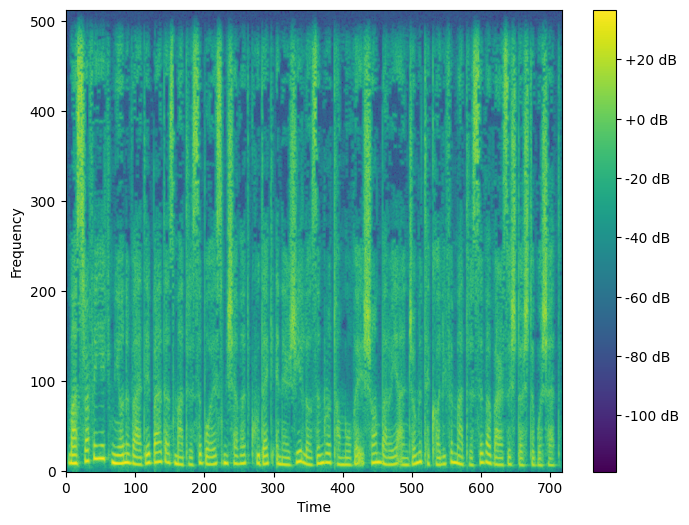

In [184]:
audio_file = audio_files[12]
waveform , sr = load_normalize(audio_file)
waveform = remove_silence(waveform , sr)
spec = spectrogram(waveform)

spec = spec[0].detach().numpy()
plt.figure(figsize = (8,6))
plt.imshow(20 * np.log10(spec + 1e-6), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

In [178]:
mel_specs = []
for audio_file in tqdm(audio_files):
    waveform, sr = load_normalize(audio_file)

    waveform = remove_silence(waveform, sr)
    mel_db = mel_filter_bank(waveform)
    mel_specs.append(mel_db)


100%|██████████| 11135/11135 [05:04<00:00, 36.62it/s]
